# Описание алгоритмов

M — размер первого массива `arr1`, N — размер второго массива `arr2`, M ≤ N.

| Алгоритм | Суть | Время | Память |
|---|---|---|---|
| Два указателя (`two_pointers`) | Идём по обоим массивам одновременно и сдвигаем указатель, стоящий на меньшем элементе. Если элементы под указателями равны — общий элемент найден. | O(M + N) | O(1) |
| Бинарный поиск (`binary_steps`) | Для каждого элемента первого массива бинарным поиском ищем его во втором массиве. | O(M · log N) | O(1) |
| Экспоненциальный поиск (`galloping_search`) | Как два указателя, но указатель во втором массиве прыгает шагами 1, 2, 4, 8, … пока не перескочит искомый элемент, после чего найденный отрезок досматривается бинарным поиском. | O(M + M · log(N / M)) | O(1) |
| Двойной бинарный поиск (`two_binary_search`) | Берём средний элемент первого массива, бинарным поиском находим его место во втором массиве и рекурсивно решаем задачу для левых и для правых половин, передавая границы половин. | O(M + M · log(N / M)) | O(log M) на стек рекурсии |

In [57]:
base_test_case_1 = ([1, 2, 3], [4, 5, 6])
base_test_case_2 = ([1, 2, 3], [3, 7, 8])
base_test_case_3 = ([], [])

# Два указателя

In [58]:
def two_pointers(arr1, arr2):
    first_pointer = 0
    second_pointer = 0
    while first_pointer < len(arr1) and second_pointer < len(arr2):
        if arr1[first_pointer] == arr2[second_pointer]:
            return True
        elif arr1[first_pointer] < arr2[second_pointer]:
            first_pointer += 1
        else:
            second_pointer += 1

    return False


In [59]:
print(two_pointers(*base_test_case_1))
print(two_pointers(*base_test_case_2))
print(two_pointers(*base_test_case_3))

False
True
False


# Бинарный поиск

In [60]:
def binary_search(arr, target, left, right):
    while left <= right:
        mid = (left + right) // 2

        if arr[mid] == target:
            return mid
        elif arr[mid] < target:
            left = mid + 1
        else:
            right = mid - 1

    return left


In [61]:
def binary_steps(arr1, arr2):
    for element in arr1:
        if binary_search(arr2, element, 0, len(arr2) - 1) < len(arr2) and arr2[binary_search(arr2, element, 0, len(arr2) - 1)] == element:
            return True
    return False

In [62]:
print(binary_steps(*base_test_case_1))
print(binary_steps(*base_test_case_2))
print(binary_steps(*base_test_case_3))

False
True
False


# Экспоненциальный поиск

In [63]:
def galloping_search(arr1, arr2):
    if not arr1 or not arr2:
        return False

    if arr1[0] == arr2[0]:
        return True

    first_pointer = 0
    second_pointer = 0
    step = 1

    while first_pointer < len(arr1) and second_pointer < len(arr2):

        if arr1[first_pointer] == arr2[second_pointer]:
            return True

        elif arr1[first_pointer] > arr2[second_pointer]:
            next_pointer = second_pointer + step

            if next_pointer < len(arr2) and arr2[next_pointer] < arr1[first_pointer]:
                second_pointer = next_pointer
                step *= 2
            else:
                left = second_pointer + 1
                right = min(next_pointer, len(arr2) - 1)

                idx = binary_search(arr2, arr1[first_pointer], left, right)

                if idx < len(arr2) and arr2[idx] == arr1[first_pointer]:
                    return True

                second_pointer = idx
                step = 1

        else:
            first_pointer += 1

    return False

In [64]:
print(galloping_search(*base_test_case_1))
print(galloping_search(*base_test_case_2))
print(galloping_search(*base_test_case_3))

False
True
False


# Двойной бинарный поиск

In [65]:
def two_binary_search(arr1, arr2):
    def search(left1, right1, left2, right2):
        if left1 > right1 or left2 > right2:
            return False

        mid = (left1 + right1) // 2
        ind = binary_search(arr2, arr1[mid], left2, right2)

        if ind <= right2 and arr2[ind] == arr1[mid]:
            return True

        return search(left1, mid - 1, left2, ind - 1) or search(mid + 1, right1, ind, right2)

    return search(0, len(arr1) - 1, 0, len(arr2) - 1)

In [66]:
print(two_binary_search(*base_test_case_1))
print(two_binary_search(*base_test_case_2))
print(two_binary_search(*base_test_case_3))

False
True
False


# Исследование производительности

Во всех замерах используется худший случай: массивы не имеют общих элементов, в `arr1` только нечётные числа, в `arr2` только чётные (0, 2, 4, …), и числа `arr1` равномерно распределены по всему диапазону `arr2`. Ни один алгоритм не может завершиться досрочно. Меньший массив всегда передаётся первым аргументом.

Каждый алгоритм на каждой паре массивов запускается несколько раз (5 раз для массивов одинакового размера, 30 раз для разного соотношения размеров, где замеры короткие), берётся минимальное время.

In [67]:
import time

import matplotlib.pyplot as plt
import pandas as pd

In [68]:
algorithms = {
    "Два указателя": two_pointers,
    "Бинарный поиск": binary_steps,
    "Экспоненциальный поиск": galloping_search,
    "Двойной бинарный поиск": two_binary_search,
}

In [69]:
"Нечётные числа равномерно по чётным."

def make_arrays(size1, size2):
    arr1 = [2 * (i * size2 // size1) + 1 for i in range(size1)]
    arr2 = [2 * i for i in range(size2)]
    
    return arr1, arr2

In [70]:
"Лучшее время работы, мс."

def measure(func, arr1, arr2, repeats):
    best = float("inf")
    
    for _ in range(repeats):
        start = time.perf_counter()
        func(arr1, arr2)
        best = min(best, time.perf_counter() - start)

    return best * 1000

In [71]:
"Замеры всех алгоритмов."

def run_experiment(sizes, repeats):
    results = {name: [] for name in algorithms}

    for size1, size2 in sizes:
        arr1, arr2 = make_arrays(size1, size2)

        for name, func in algorithms.items():
            results[name].append(measure(func, arr1, arr2, repeats))
            
    return results

In [72]:
"Таблица результатов."

def make_table(params, results):
    table = pd.DataFrame(params | results)
    table["Лучший"] = table[list(algorithms)].idxmin(axis=1)
    
    return table

In [73]:
"График времени работы."

def plot_results(x, results, title, xlabel, xticklabels):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for name, times in results.items():
        ax.plot(x, times, label=name, marker="o")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(xticklabels, rotation=45)
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Время, мс")
    ax.grid(True)
    ax.legend()

    plt.show()

## Массивы одинакового размера

Оба массива имеют одинаковый размер n, n меняется от 10 до 1 000 000. Ячейка с замерами выполняется около минуты.

In [74]:
sizes = [10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000, 300000, 1000000]

In [75]:
results_equal = run_experiment([(size, size) for size in sizes], repeats=5)

In [76]:
make_table({"n": sizes}, results_equal)

,n,Два указателя,Бинарный поиск,Экспоненциальный поиск,Двойной бинарный поиск,Лучший
0,10,0.002400,0.012100,0.006400,0.007600,Два указателя
1,30,0.007600,0.045400,0.022000,0.022400,Два указателя
2,100,0.022500,0.193500,0.073700,0.055600,Два указателя
3,300,0.087699,0.780600,0.219900,0.203000,Два указателя
4,1000,0.357100,3.039898,0.594399,0.527400,Два указателя
5,3000,1.089499,7.647898,1.659499,1.537300,Два указателя
6,10000,2.253699,30.030690,5.536798,5.420098,Два указателя
7,30000,6.621597,96.048769,16.989394,16.218694,Два указателя
8,100000,22.711893,387.866162,58.572279,53.982881,Два указателя
9,300000,69.381575,1209.216351,176.452401,171.536094,Два указателя


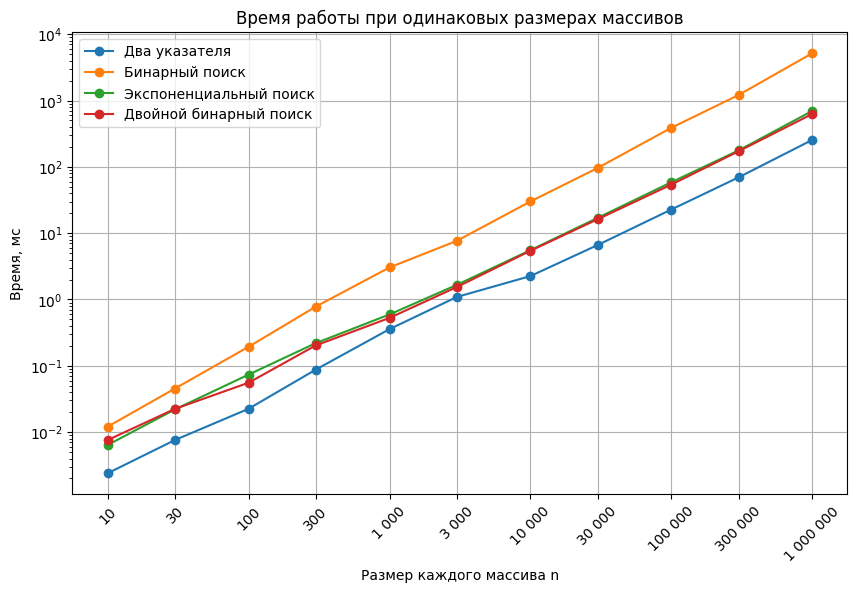

In [77]:
plot_results(
    sizes,
    results_equal,
    title="Время работы при одинаковых размерах массивов",
    xlabel="Размер каждого массива n",
    xticklabels=[f"{size:,}".replace(",", " ") for size in sizes],
)

## Разное соотношение размеров массивов

Размер первого массива M, размер второго N = M, 2M, 4M, 8M, … — множитель удваивается, пока N не дойдёт примерно до миллиона. Замеры проводятся для M = 1000 (N до 1024M = 1 024 000) и M = 30 (N до 32768M = 983 040).

In [78]:
ratios_m1000 = [2 ** k for k in range(11)]  # 1 ... 1024
ratios_m30 = [2 ** k for k in range(16)]    # 1 ... 32768

### M = 1000

In [79]:
results_m1000 = run_experiment([(1000, ratio * 1000) for ratio in ratios_m1000], repeats=30)

In [80]:
make_table({"N / M": ratios_m1000, "N": [ratio * 1000 for ratio in ratios_m1000]}, results_m1000)

,N / M,N,Два указателя,Бинарный поиск,Экспоненциальный поиск,Двойной бинарный поиск,Лучший
0,1,1000,0.228000,2.204200,0.554800,0.517800,Два указателя
1,2,2000,0.326100,2.377100,0.760600,0.561699,Два указателя
2,4,4000,0.579700,2.751600,1.106200,0.716200,Два указателя
3,8,8000,0.953299,2.960100,1.292399,0.735100,Двойной бинарный поиск
4,16,16000,1.813099,3.041499,1.680199,0.896499,Двойной бинарный поиск
5,32,32000,3.539799,3.167900,1.823499,0.968200,Двойной бинарный поиск
6,64,64000,7.269299,3.561099,2.150600,1.093500,Двойной бинарный поиск
7,128,128000,15.199098,4.129999,2.529500,1.224200,Двойной бинарный поиск
8,256,256000,29.987396,4.315599,2.675399,1.306300,Двойной бинарный поиск
9,512,512000,60.540190,4.677999,3.227199,1.624199,Двойной бинарный поиск


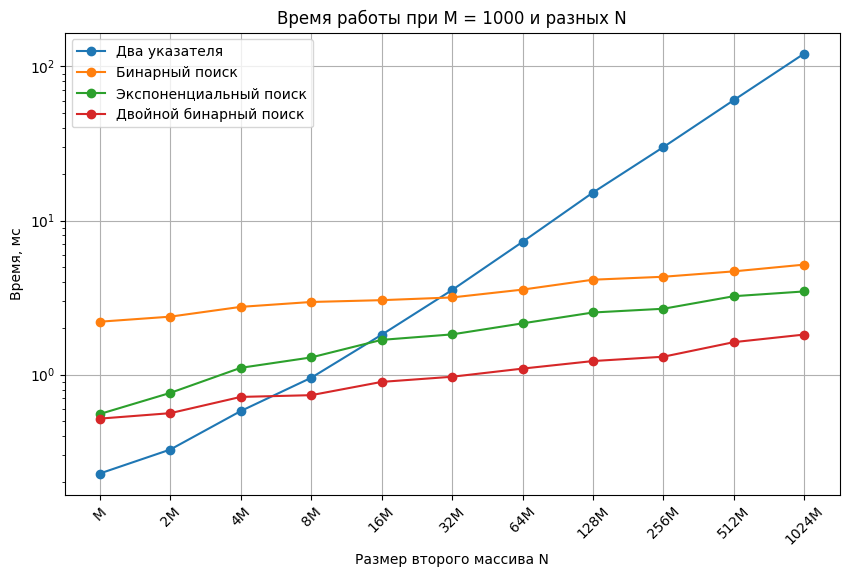

In [81]:
plot_results(
    ratios_m1000,
    results_m1000,
    title="Время работы при M = 1000 и разных N",
    xlabel="Размер второго массива N",
    xticklabels=[f"{ratio}M" if ratio > 1 else "M" for ratio in ratios_m1000],
)

### M = 30

In [82]:
results_m30 = run_experiment([(30, ratio * 30) for ratio in ratios_m30], repeats=30)

In [83]:
make_table({"N / M": ratios_m30, "N": [ratio * 30 for ratio in ratios_m30]}, results_m30)

,N / M,N,Два указателя,Бинарный поиск,Экспоненциальный поиск,Двойной бинарный поиск,Лучший
0,1,30,0.005000,0.027100,0.011500,0.012400,Два указателя
1,2,60,0.007700,0.032200,0.016200,0.013300,Два указателя
2,4,120,0.012800,0.042400,0.023300,0.016400,Два указателя
3,8,240,0.025000,0.047100,0.032000,0.020500,Двойной бинарный поиск
4,16,480,0.045800,0.058400,0.040000,0.023500,Двойной бинарный поиск
5,32,960,0.090300,0.058700,0.045000,0.025200,Двойной бинарный поиск
6,64,1920,0.175000,0.065800,0.053900,0.027699,Двойной бинарный поиск
7,128,3840,0.335900,0.083100,0.070100,0.036000,Двойной бинарный поиск
8,256,7680,0.726000,0.086000,0.073600,0.036400,Двойной бинарный поиск
9,512,15360,1.568000,0.092700,0.086000,0.041700,Двойной бинарный поиск


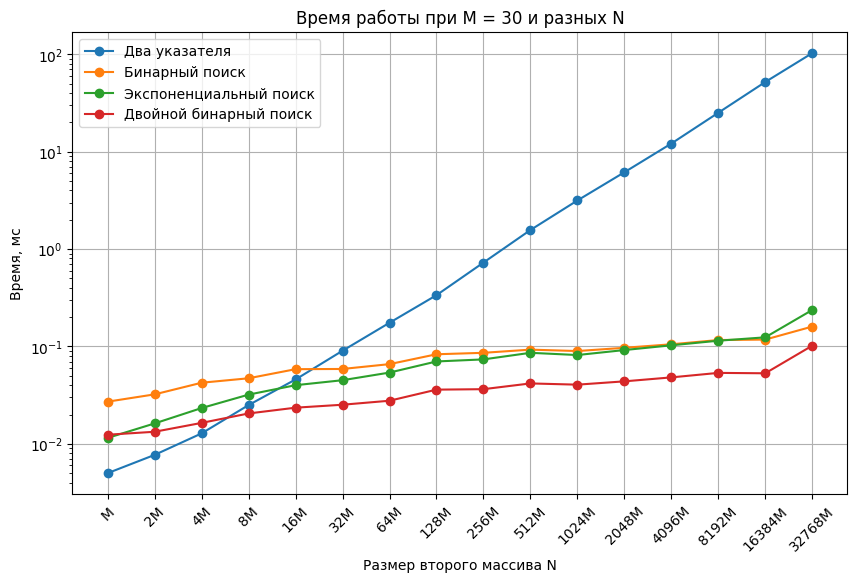

In [84]:
plot_results(
    ratios_m30,
    results_m30,
    title="Время работы при M = 30 и разных N",
    xlabel="Размер второго массива N",
    xticklabels=[f"{ratio}M" if ratio > 1 else "M" for ratio in ratios_m30],
)

# Выводы

**Массивы одинакового размера**

- **Два указателя быстрее всех при любом n** — от 10 до 1 000 000 элементов. Когда M = N, асимптотически все алгоритмы, кроме бинарного поиска, линейны, и выигрывает тот, у кого шаг дешевле.
- **Двойной бинарный и экспоненциальный поиск** идут почти вровень (двойной бинарный немного быстрее) и медленнее двух указателей примерно в 2–3 раза; это отношение почти не зависит от n.
- **Бинарный поиск** отстаёт сильнее всех, и отставание растёт с n: примерно в 5 раз при n = 10 и примерно в 18 раз при n = 1 000 000. Это множитель log n из сложности O(n · log n).

**Разное соотношение размеров массивов (M = 1000 и M = 30, N до ~1 000 000)**

| N / M | Лучший алгоритм |
|---|---|
| 1, 2, 4 | Два указателя |
| от 8 и далее | Двойной бинарный поиск |

- **Картина одинакова для M = 1000 и M = 30:** лучший алгоритм зависит от соотношения N / M, а не от абсолютных размеров массивов. Граница, после которой два указателя перестают быть лучшими, в обоих случаях находится между 4M и 8M.
- **Два указателя** при близких размерах самые быстрые, но их время растёт линейно с N. При N ≈ 1 000 000 они медленнее двойного бинарного поиска примерно в 70 раз при M = 1000 и более чем в 1000 раз при M = 30.
- **Бинарный поиск** почти не зависит от N (растёт как log N), но при близких размерах самый медленный: на каждый элемент первого массива выполняется полный бинарный поиск по всему второму массиву. Два указателя он обгоняет с N = 32M.
- **Экспоненциальный поиск** обгоняет два указателя с N = 16M. При очень большой разнице размеров (N / M ≥ 1000 при M = 30) он сравнивается по времени с бинарным поиском: прыжков становится около log(N / M) ≈ log N, и он фактически превращается в обычный бинарный поиск.
- **Двойной бинарный поиск** быстрее всех начиная с N = 8M и до N ≈ 1 000 000, примерно в 2 раза быстрее экспоненциального: каждый бинарный поиск сужает область второго массива для обеих половин первого, поэтому следующие поиски идут по всё более коротким отрезкам. Асимптотика у него та же, что у экспоненциального поиска, — O(M · log(N / M)), поэтому разница между ними определяется деталями реализации, а не алгоритмом.

**Итог:** если размеры массивов близки (N ≤ 4M), лучше использовать два указателя; если один массив намного больше другого (N ≥ 8M) — двойной бинарный поиск. Если соотношение заранее неизвестно, лучший выбор — двойной бинарный поиск: при равных размерах он проигрывает двум указателям примерно в 2–2,5 раза, а при большой разнице выигрывает у всех, причём у двух указателей — на порядки. При этом стоит помнить, что двойной бинарный поиск - единственный алгоритм с затратами по памяти отличными от O(1), а именно O(log M).